# Nashik after dark — night-time lights × population exposure, 2020
**Question 2 · Individual Google Earth Engine Urban Analysis**

**Task (row 18):** Estimate the total population of Nashik and the population residing in the **highest quartile of night-time radiance** in 2020.

| Item | Choice |
|---|---|
| City / ULB | Nashik Municipal Corporation (NMC), Maharashtra |
| Night-time lights | `NOAA/VIIRS/DNB/ANNUAL_V21` (annual composite, `average_masked`) and `NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG` (monthly, `avg_rad` + `cf_cvg`) |
| Population | `WorldPop/GP/100m/pop` — India, 2020 (people per ~100 m cell) |
| "Relatively high" rule | VIIRS pixels inside the boundary with 2020 annual radiance ≥ the **city-specific 75th percentile** (top quartile, unweighted by area) |
| Dynamic output | 12-month 2020 radiance GIF + frame-by-frame time slider on the webpage, and a radiance ↔ population swipe |

> Interpretation rule used throughout: results are reported as **population residing in areas with relatively high satellite-observed night-time radiance** — not as anybody's personal or ground-level exposure.

Running this notebook end-to-end writes every figure, the GIF, CSVs and `results.json` into `site/`, which is the webpage folder.

## 0 · Setup — activate Earth Engine
Same activation lines as the class-practice notebook. `ee.Authenticate()` opens a Google sign-in link the first time; approve it with the account that owns the project, then `ee.Initialize` connects.

In [1]:
pip install earthengine-api

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [2]:
pip install geemap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install geopandas osmnx matplotlib imageio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
import ee
import geemap

In [5]:
PROJECT_ID="fresh-thinker-510708-p6"

In [6]:
ee.Authenticate()

True

In [7]:
ee.Initialize(project=PROJECT_ID)

print("Google Earth Engine initialized successfully.")

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Google Earth Engine initialized successfully.


In [8]:
message = ee.String("Connected to Google Earth Engine")

print(message.getInfo())

Connected to Google Earth Engine


In [9]:
# ----------------------------- CONFIG -----------------------------
STUDENT_NAME = "Susovan Maity"
ROLL_NO      = "CS25M258"

CITY   = "Nashik"
YEAR   = 2020

# Boundary: put an official ULB file here (GeoJSON/SHP/GPKG) to use it instead of OSM.
# Official ULB boundary shipped with this project (keep it next to the notebook):
# Nashik Municipal Corporation, ULB code 802776, from the Swachh Bharat Mission (Urban) ULB layer
# in the suggested "Indian urban-boundary release" (github.com/yashveeeeeeer/india-geodata, release urban/boundaries, SBM_ULBs).
BOUNDARY_FILE = "nashik_nmc_boundary.geojson"
BOUNDARY_NAME_FIELD = None      # optional: column to filter on
BOUNDARY_NAME_VALUE = None
OSM_QUERY = "Nashik Municipal Corporation, Maharashtra, India"
OSM_FALLBACK_QUERY = "Nashik, Nashik District, Maharashtra, India"

OUT = "site"                    # webpage folder (index.html lives here)
VMAX_RAD = None                 # fixed colour-scale max (nW/cm²/sr); None = 99th pct of all 2020 frames
UTM = "EPSG:32643"              # UTM zone 43N, for areas in km²
# ------------------------------------------------------------------

In [10]:
import os, json, math, datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.patches import Patch
import imageio.v2 as imageio

os.makedirs(f"{OUT}/assets/frames", exist_ok=True)
os.makedirs(f"{OUT}/downloads", exist_ok=True)

print("Libraries ready · Earth Engine project:", PROJECT_ID)


Libraries ready · Earth Engine project: fresh-thinker-510708-p6


## 1 · City boundary → GeoDataFrame → Earth Engine geometry
**Boundary source:** Nashik Municipal Corporation (ULB code 802776) from the Swachh Bharat Mission (Urban) ULB layer, distributed in the suggested Indian urban-boundary release (`india-geodata`, release `urban/boundaries`, file `SBM_ULBs`). It is saved as `nashik_nmc_boundary.geojson` next to this notebook (≈267 km²). If that file is missing the cell falls back to OpenStreetMap, accepting only a 50–500 km² polygon that contains central Nashik.

  ✓ nashik_nmc_boundary.geojson | 267.3 km²
Nashik Municipal Corporation (ULB code 802776), Swachh Bharat Mission (Urban) ULB boundary layer, from the Indian urban-boundary release (india-geodata, release urban/boundaries, SBM_ULBs)
Area: 267.25 km²  |  bbox: 73.6868,19.9058,73.9024,20.0832


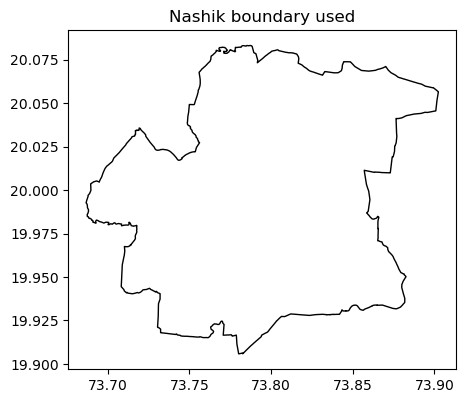

In [11]:
MIN_CITY_KM2 = 50     # smaller = a building or ward, not the city
MAX_CITY_KM2 = 500    # larger = Nashik taluka/district, not the municipal corporation (NMC is ~260–270 km²)
from shapely.geometry import Point as _Pt
NASHIK_CENTRE = _Pt(73.79, 19.99)   # lon, lat near the old city / Panchavati

def _area_km2(g):
    return float(g.to_crs(UTM).area.sum() / 1e6)

def load_boundary():
    if BOUNDARY_FILE and not os.path.exists(BOUNDARY_FILE):
        print(f"  ! {BOUNDARY_FILE} not found in {os.getcwd()} — put it next to the notebook. Trying OpenStreetMap instead.")
    if BOUNDARY_FILE and os.path.exists(BOUNDARY_FILE):
        g = gpd.read_file(BOUNDARY_FILE)
        if g.crs is None:
            g = g.set_crs(4326)
        if BOUNDARY_NAME_FIELD and BOUNDARY_NAME_VALUE:
            g = g[g[BOUNDARY_NAME_FIELD].astype(str).str.contains(BOUNDARY_NAME_VALUE, case=False)]
        g = g.to_crs(4326)
        print(f"  ✓ {BOUNDARY_FILE} | {_area_km2(g):.1f} km²")
        if "ulbcode" in g.columns and str(g["ulbcode"].iloc[0]) == "802776":
            src = ("Nashik Municipal Corporation (ULB code 802776), Swachh Bharat Mission (Urban) ULB boundary layer, "
                   "from the Indian urban-boundary release (india-geodata, release urban/boundaries, SBM_ULBs)")
        else:
            src = f"User-supplied ULB file: {os.path.basename(BOUNDARY_FILE)}"
        return g, src
    import osmnx as ox
    queries = [
        {"city": "Nashik", "state": "Maharashtra", "country": "India"},   # structured query -> admin boundary
        "Nashik, Maharashtra, India",
        OSM_QUERY,
        OSM_FALLBACK_QUERY,
    ]
    for q in queries:
        try:
            g = ox.geocode_to_gdf(q).to_crs(4326)
        except Exception as e:
            print("  ✗", q, "->", e); continue
        g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])]
        if g.empty:
            print("  ✗", q, "-> not a polygon"); continue
        a = _area_km2(g)
        shape = g.union_all() if hasattr(g, 'union_all') else g.unary_union
        ok = (MIN_CITY_KM2 <= a <= MAX_CITY_KM2) and shape.contains(NASHIK_CENTRE)
        print(f"  {'✓' if ok else '✗'} {q} -> {g['display_name'].iloc[0]} | "
              f"{g.get('class', pd.Series(['?'])).iloc[0]}/{g.get('type', pd.Series(['?'])).iloc[0]} | {a:.1f} km²")
        if ok:
            osm_id = g.get("osm_id", pd.Series(["?"])).iloc[0]
            return g, (f"OpenStreetMap administrative boundary '{g['display_name'].iloc[0]}' "
                       f"(OSM relation {osm_id}), retrieved {datetime.date.today()} via OSMnx; © OpenStreetMap contributors, ODbL")
    raise RuntimeError("No city-sized (50–500 km²) boundary containing central Nashik found on OSM — download the NMC boundary file and set BOUNDARY_FILE.")

city_gdf, BOUNDARY_SOURCE = load_boundary()
city_gdf = city_gdf.to_crs(4326)
city_gdf = gpd.GeoDataFrame(geometry=[city_gdf.union_all() if hasattr(city_gdf, "union_all") else city_gdf.unary_union], crs=4326)
city_area_km2 = float(city_gdf.to_crs(UTM).area.iloc[0] / 1e6)
city_gdf.to_file(f"{OUT}/assets/boundary.geojson", driver="GeoJSON")

geom = ee.Geometry(city_gdf.geometry.iloc[0].__geo_interface__)
city_fc = ee.FeatureCollection([ee.Feature(geom)])
minx, miny, maxx, maxy = city_gdf.total_bounds
print(BOUNDARY_SOURCE)
assert MIN_CITY_KM2 <= city_area_km2 <= MAX_CITY_KM2, f"Boundary is {city_area_km2:.2f} km² — not the NMC city limit"
print(f"Area: {city_area_km2:.2f} km²  |  bbox: {minx:.4f},{miny:.4f},{maxx:.4f},{maxy:.4f}")
city_gdf.plot(figsize=(5, 5), edgecolor="k", facecolor="none"); plt.title("Nashik boundary used"); plt.show()

## 2 · Datasets and filters
* **Temporal filter:** calendar year 2020 for every dataset.
* **Annual lights:** `average_masked` from VIIRS annual V2.1 — background (unlit) pixels set to zero, outliers such as fires and aurora removed, stray-light corrected. This is the basis of the quartile rule.
* **Monthly lights:** stray-light-corrected monthly composites (`vcmslcfg`). Quality filter: a pixel-month is used only if it had **≥ 1 cloud-free observation** (`cf_cvg ≥ 1`); negative radiance from noise is clamped to 0.
* **Population:** WorldPop unconstrained 100 m estimate for India, 2020.

In [12]:
annual_col = (ee.ImageCollection("NOAA/VIIRS/DNB/ANNUAL_V21")
              .filterDate(f"{YEAR}-01-01", f"{YEAR+1}-01-01"))
print("Annual images:", annual_col.size().getInfo())
annual_raw = annual_col.first()
ntl = annual_raw.select("average_masked").max(0).rename("rad")
NTL_PROJ  = annual_raw.select("average_masked").projection()
NTL_SCALE = NTL_PROJ.nominalScale().getInfo()

monthly = (ee.ImageCollection("NOAA/VIIRS/DNB/MONTHLY_V1/VCMSLCFG")
           .filterDate(f"{YEAR}-01-01", f"{YEAR+1}-01-01")
           .sort("system:time_start"))
print("Monthly images:", monthly.size().getInfo())

def clean_month(img):
    good = img.select("cf_cvg").gte(1)
    rad = img.select("avg_rad").max(0).updateMask(good).rename("rad")
    return rad.addBands(img.select("cf_cvg")).copyProperties(img, ["system:time_start"])
monthly_clean = monthly.map(clean_month)

pop = (ee.ImageCollection("WorldPop/GP/100m/pop")
       .filter(ee.Filter.eq("country", "IND"))
       .filter(ee.Filter.eq("year", YEAR))
       .first().select("population"))
POP_PROJ  = pop.projection()
POP_SCALE = POP_PROJ.nominalScale().getInfo()
print(f"VIIRS scale ≈ {NTL_SCALE:.1f} m, WorldPop scale ≈ {POP_SCALE:.1f} m")

Annual images: 1
Monthly images: 12
VIIRS scale ≈ 463.8 m, WorldPop scale ≈ 92.8 m


## 3 · Quartile rule, exposure and summary statistics
1. Percentiles (25/50/75) of 2020 annual radiance over the VIIRS pixels inside the boundary.
2. **High-radiance zone** = pixels with radiance ≥ P75.
3. The zone mask is applied to the 100 m population grid (nearest-neighbour; each ~100 m cell takes the class of the VIIRS pixel it falls in) and population is summed.

In [13]:
pct = ntl.reduceRegion(ee.Reducer.percentile([25, 50, 75]), geom, crs=NTL_PROJ, maxPixels=1e10).getInfo()
P25, P50, P75 = pct["rad_p25"], pct["rad_p50"], pct["rad_p75"]
print(f"P25={P25:.2f}  P50={P50:.2f}  P75={P75:.2f}  nW/cm²/sr")

# quartile class 1..4 (4 = highest)
qcls = (ee.Image(1).where(ntl.gte(P25), 2).where(ntl.gte(P50), 3).where(ntl.gte(P75), 4)
        .updateMask(ntl.mask()).rename("q").toInt())
high = ntl.gte(P75).selfMask().rename("high")

def rr(img, reducer, proj, **kw):
    return img.reduceRegion(reducer, geom, crs=proj, maxPixels=1e10, **kw)

total_pop   = rr(pop, ee.Reducer.sum(), POP_PROJ).get("population")
exposed_pop = rr(pop.updateMask(ntl.gte(P75)), ee.Reducer.sum(), POP_PROJ).get("population")
popw_rad    = rr(ntl.multiply(pop).rename("rp"), ee.Reducer.sum(), POP_PROJ).get("rp")
city_stats  = rr(ntl, ee.Reducer.mean().combine(ee.Reducer.max(), "", True).combine(ee.Reducer.count(), "", True), NTL_PROJ)
high_area   = rr(ee.Image.pixelArea().updateMask(high), ee.Reducer.sum(), NTL_PROJ).get("area")

# population & area by quartile class (grouped reducers)
pop_by_q  = rr(pop.addBands(qcls), ee.Reducer.sum().group(groupField=1, groupName="q"), POP_PROJ).get("groups")
area_by_q = rr(ee.Image.pixelArea().addBands(qcls), ee.Reducer.sum().group(groupField=1, groupName="q"), NTL_PROJ).get("groups")

S = ee.Dictionary(dict(total_pop=total_pop, exposed_pop=exposed_pop, popw_rad=popw_rad,
                       city=city_stats, high_area=high_area, pop_by_q=pop_by_q, area_by_q=area_by_q)).getInfo()

TOTAL_POP, EXPOSED_POP = S["total_pop"], S["exposed_pop"]
SHARE = 100 * EXPOSED_POP / TOTAL_POP
HIGH_AREA_KM2 = S["high_area"] / 1e6
POPW_RAD = S["popw_rad"] / TOTAL_POP
CITY_MEAN, CITY_MAX, N_PIX = S["city"]["rad_mean"], S["city"]["rad_max"], S["city"]["rad_count"]

quart = pd.DataFrame({
    "quartile": [1, 2, 3, 4],
    "label": ["Q1 (darkest)", "Q2", "Q3", "Q4 (brightest)"],
    "radiance_range": [f"< {P25:.2f}", f"{P25:.2f}–{P50:.2f}", f"{P50:.2f}–{P75:.2f}", f"≥ {P75:.2f}"],
})
pq = {int(g["q"]): g["sum"] for g in S["pop_by_q"]}
aq = {int(g["q"]): g["sum"] / 1e6 for g in S["area_by_q"]}
quart["population"] = quart["quartile"].map(pq).fillna(0)
quart["area_km2"]   = quart["quartile"].map(aq).fillna(0)
quart["pop_share_pct"]  = 100 * quart["population"] / quart["population"].sum()
quart["area_share_pct"] = 100 * quart["area_km2"] / quart["area_km2"].sum()
quart["density_per_km2"] = quart["population"] / quart["area_km2"]

print(f"Total population (WorldPop 2020): {TOTAL_POP:,.0f}")
print(f"Population in highest-radiance quartile: {EXPOSED_POP:,.0f}  ({SHARE:.1f}%)")
print(f"High-radiance zone area: {HIGH_AREA_KM2:.2f} km² of {city_area_km2:.2f} km²")
quart

P25=4.10  P50=9.59  P75=19.11  nW/cm²/sr
Total population (WorldPop 2020): 1,598,886
Population in highest-radiance quartile: 876,327  (54.8%)
High-radiance zone area: 65.77 km² of 267.25 km²


,quartile,label,radiance_range,population,area_km2,pop_share_pct,area_share_pct,density_per_km2
0,1,Q1 (darkest),< 4.10,61643.402079,66.308407,3.855397,24.808229,929.646859
1,2,Q2,4.10–9.59,180063.153504,66.675512,11.261787,24.945575,2700.589006
2,3,Q3,9.59–19.11,480852.999352,68.525085,30.074248,25.637563,7017.182062
3,4,Q4 (brightest),≥ 19.11,876326.616100,65.774920,54.808568,24.608633,13323.111768


## 4 · Monthly 2020 time series (city-wide), with data availability
For each month: mean radiance of usable pixels, share of the city's VIIRS pixels with **no** cloud-free observation, and mean number of cloud-free observations. Monsoon months are expected to be the weakest — the table makes that explicit rather than hiding it.

In [14]:
def month_stats(img):
    img = ee.Image(img)
    rad = img.select("rad"); cf = img.select("cf_cvg")
    d = ee.Dictionary({
        "month": ee.Date(img.get("system:time_start")).format("YYYY-MM"),
        "mean_rad": rad.reduceRegion(ee.Reducer.mean(), geom, crs=NTL_PROJ, maxPixels=1e10).get("rad"),
        "p75_rad":  rad.reduceRegion(ee.Reducer.percentile([75]), geom, crs=NTL_PROJ, maxPixels=1e10).get("rad"),
        "mean_cf":  cf.reduceRegion(ee.Reducer.mean(), geom, crs=NTL_PROJ, maxPixels=1e10).get("cf_cvg"),
        "nodata_pct": cf.lt(1).reduceRegion(ee.Reducer.mean(), geom, crs=NTL_PROJ, maxPixels=1e10).get("cf_cvg"),
    })
    return ee.Feature(None, d)

mfc = ee.FeatureCollection(monthly_clean.map(month_stats)).getInfo()
mdf = pd.DataFrame([f["properties"] for f in mfc["features"]])
for col in ["mean_rad", "p75_rad", "mean_cf", "nodata_pct"]:
    mdf[col] = pd.to_numeric(mdf.get(col), errors="coerce")   # months with no data -> NaN, not None
mdf = mdf.sort_values("month").reset_index(drop=True)
assert len(mdf) == 12, f"Expected 12 monthly composites for {YEAR}, got {len(mdf)}"
mdf["nodata_pct"] = 100 * mdf["nodata_pct"]
mdf["month_name"] = pd.to_datetime(mdf["month"]).dt.strftime("%b")
mdf

,mean_cf,mean_rad,month,nodata_pct,p75_rad,month_name
0,18.543790,13.609661,2020-01,0.000000,21.195882,Jan
1,17.609839,13.774079,2020-02,0.000000,21.090000,Feb
2,17.178254,13.025843,2020-03,0.000000,20.145000,Mar
3,17.364889,12.702550,2020-04,0.000000,19.630000,Apr
4,12.780630,12.730931,2020-05,0.000000,19.886363,May
5,1.151197,10.903788,2020-06,19.755659,16.175000,Jun
6,2.046891,9.337375,2020-07,0.316346,14.141250,Jul
7,1.027606,6.540146,2020-08,21.314663,9.130000,Aug
8,0.170714,10.459298,2020-09,82.928557,15.335000,Sep
9,7.651985,7.652991,2020-10,0.000000,11.139286,Oct


## 5 · Pull rasters onto fixed grids for mapping
Every map and every GIF frame is drawn on the **same extent and same colour scale**. Rasters are sampled onto explicit EPSG:4326 grids: the native VIIRS 15″ grid (~463 m) and a 3″ (~92 m) grid for population.

In [15]:
PAD = 0.02
def grid(res):
    x0 = math.floor((minx - PAD) / res) * res
    y0 = math.ceil((maxy + PAD) / res) * res
    nx = int(math.ceil((maxx + PAD - x0) / res)); ny = int(math.ceil((y0 - (miny - PAD)) / res))
    return x0, y0, nx, ny, res

MAX_PX = 250_000   # Earth Engine sampleRectangle limit is 262,144 pixels per request

def _fetch(img, bands, x0, ytop, nx, nrows, res):
    eps = res * 1e-3
    region = ee.Geometry.Rectangle([x0 + eps, ytop - nrows * res + eps, x0 + nx * res - eps, ytop - eps], None, False)
    im = img.select(bands).reproject(crs="EPSG:4326", crsTransform=[res, 0, x0, 0, -res, ytop]).unmask(-9999)
    props = im.sampleRectangle(region=region, defaultValue=-9999).getInfo()["properties"]
    return {b: np.array(props[b], dtype=float) for b in bands}

def sample(img, res, bands):
    """Download img on a fixed EPSG:4326 grid, in horizontal strips so no request exceeds the EE limit."""
    x0, y0, nx, ny, res = grid(res)
    rows_per = max(1, MAX_PX // (nx * max(1, len(bands) // 4 + 1)))
    parts = {b: [] for b in bands}
    for r0 in range(0, ny, rows_per):
        n = min(rows_per, ny - r0)
        got = _fetch(img, bands, x0, y0 - r0 * res, nx, n, res)
        for b in bands: parts[b].append(got[b])
    out = {}
    for b in bands:
        a = np.vstack(parts[b]); a[a <= -9998] = np.nan; out[b] = a
    r, c = out[bands[0]].shape
    extent = [x0, x0 + c * res, y0 - r * res, y0]
    return out, extent

R_NTL, R_POP = 1 / 240, 1 / 1200
A, EXT = sample(ntl.addBands(qcls), R_NTL, ["rad", "q"])
month_img = monthly_clean.select("rad").toBands().rename([f"m{i:02d}" for i in range(1, 13)])
M, _ = sample(month_img, R_NTL, [f"m{i:02d}" for i in range(1, 13)])
P, EXT_POP = sample(pop, R_POP, ["population"])

# Inside-boundary mask on each grid (for clean edges in figures)
from shapely import contains_xy
def inside_mask(extent, shape):
    r, c = shape; x0, x1, y0b, y1 = extent
    xs = x0 + (np.arange(c) + .5) * (x1 - x0) / c; ys = y1 - (np.arange(r) + .5) * (y1 - y0b) / r
    X, Y = np.meshgrid(xs, ys)
    return contains_xy(city_gdf.geometry.iloc[0], X, Y)
IN_NTL = inside_mask(EXT, A["rad"].shape)
IN_POP = inside_mask(EXT_POP, P["population"].shape)

stack = np.stack([M[f"m{i:02d}"] for i in range(1, 13)])
# --- quick health check of the sampled arrays ---
print("pixels inside boundary :", int(IN_NTL.sum()))
print("annual pixels with data:", int(np.isfinite(A["rad"][IN_NTL]).sum()))
print("monthly values with data per month:", [int(np.isfinite(stack[i][IN_NTL]).sum()) for i in range(12)])
assert IN_NTL.sum() > 0, "No VIIRS pixel centres fall inside the boundary — check section 1 output"

# Colour-scale max: computed on Earth Engine (never NaN), with local fallbacks
VMAX = VMAX_RAD
if not VMAX:
    v = (monthly_clean.select("rad").max().max(ntl)
         .reduceRegion(ee.Reducer.percentile([99]), geom, crs=NTL_PROJ, maxPixels=1e10).getInfo())
    VMAX = next(iter(v.values()), None) if v else None
for cand in (np.where(IN_NTL, stack, np.nan), np.where(IN_NTL, A["rad"], np.nan)):
    if VMAX is None or not np.isfinite(VMAX) or VMAX <= 0:
        with np.errstate(all="ignore"):
            VMAX = float(np.nanpercentile(cand, 99)) if np.isfinite(cand).any() else None
if VMAX is None or not np.isfinite(VMAX) or VMAX <= 0:
    VMAX = 60.0   # last-resort fixed scale (nW/cm²/sr), typical for an Indian city core
VMAX = float(VMAX)
print("Fixed radiance scale: 0 –", round(VMAX, 1), "nW/cm²/sr")

pixels inside boundary : 1326
annual pixels with data: 1326
monthly values with data per month: [1326, 1326, 1326, 1326, 1326, 1072, 1323, 1029, 239, 1326, 1326, 1326]
Fixed radiance scale: 0 – 54.9 nW/cm²/sr


## 6 · Thematic maps (fixed scale, units, legend, boundary, north arrow, scale bar)

In [16]:
BG, INK, MUTE, LIME = "#04060d", "#e8f0ff", "#7f8db3", "#c6ff3d"   # blue = light, magenta = people, lime = exposed
RAD_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "lights", ["#04060d", "#071a4a", "#0b3bb3", "#1f6bff", "#39c6ff", "#a8ecff", "#ffffff"])
POP_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "people", ["#04060d", "#2a0a3a", "#6b0f6e", "#b5179e", "#ff3fb4", "#ffc2ea"])
plt.rcParams.update({"font.family": "DejaVu Sans", "text.color": INK, "axes.labelcolor": MUTE,
                     "xtick.color": MUTE, "ytick.color": MUTE, "axes.edgecolor": "#1a2340"})
RAD_NORM = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=VMAX)

def km_per_deg_lon(lat): return 111.32 * math.cos(math.radians(lat))

def decorate(ax, extent, title, subtitle=None):
    city_gdf.boundary.plot(ax=ax, color="white", linewidth=1.3)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / math.cos(math.radians((extent[2] + extent[3]) / 2)))
    ax.set_facecolor(BG); ax.tick_params(labelsize=7)
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", color=INK, pad=14)
    if subtitle: ax.text(0, 1.012, subtitle, transform=ax.transAxes, fontsize=8, color=MUTE)
    # north arrow
    ax.annotate("N", xy=(0.94, 0.95), xytext=(0.94, 0.85), xycoords="axes fraction", ha="center", color=INK,
                fontsize=9, fontweight="bold", arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2))
    # 5 km scale bar
    lat = (extent[2] + extent[3]) / 2; L = 5 / km_per_deg_lon(lat)
    x = extent[0] + 0.05 * (extent[1] - extent[0]); y = extent[2] + 0.05 * (extent[3] - extent[2])
    ax.plot([x, x + L], [y, y], color=INK, lw=3, solid_capstyle="butt")
    ax.text(x + L / 2, y + 0.012 * (extent[3] - extent[2]), "5 km", ha="center", fontsize=7, color=INK)

def map_figure(arr, extent, cmap, norm, cbar_label, title, subtitle, fname, overlay=None):
    fig, ax = plt.subplots(figsize=(7.2, 7.2), facecolor=BG)
    im = ax.imshow(arr, extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    if overlay is not None: overlay(ax)
    decorate(ax, extent, title, subtitle)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label(cbar_label, color=MUTE, fontsize=8)
    cb.ax.tick_params(labelsize=7, colors=MUTE); cb.outline.set_edgecolor("#1a2340")
    fig.text(0.01, 0.01, f"Boundary: {BOUNDARY_SOURCE[:95]}…" if len(BOUNDARY_SOURCE) > 95 else f"Boundary: {BOUNDARY_SOURCE}",
             fontsize=6, color=MUTE)
    fig.savefig(f"{OUT}/assets/{fname}", dpi=170, facecolor=BG, bbox_inches=None)
    plt.close(fig)

rad_disp = np.where(IN_NTL, A["rad"], np.nan)
pop_disp = np.where(IN_POP, P["population"], np.nan)
high_grid = np.where(IN_NTL, (A["rad"] >= P75).astype(float), np.nan)

def high_outline(ax):
    ax.contour(np.nan_to_num(high_grid), levels=[0.5], extent=EXT,
               origin="upper", colors=[LIME], linewidths=1.4)

map_figure(rad_disp, EXT, RAD_CMAP, RAD_NORM, "Radiance (nW cm⁻² sr⁻¹), √-stretched",
           f"Night-time radiance · Nashik · {YEAR}", "VIIRS DNB annual V2.1 average_masked · ~463 m",
           "map_radiance_2020.png")
POP_NORM = mcolors.PowerNorm(gamma=0.5, vmin=0, vmax=float(np.nanpercentile(pop_disp, 99.5)))
map_figure(pop_disp, EXT, POP_CMAP, POP_NORM, "People per ~100 m cell, √-stretched",
           f"Residents · Nashik · {YEAR}", "WorldPop 100 m · lime line = top-quartile radiance zone",
           "map_population_2020.png", overlay=high_outline)

# Exposure map: population only where the top-quartile zone is, rest greyed
hi_on_pop = np.zeros_like(pop_disp, dtype=bool)
r, c = pop_disp.shape
xs = EXT_POP[0] + (np.arange(c) + .5) * (EXT_POP[1] - EXT_POP[0]) / c
ys = EXT_POP[3] - (np.arange(r) + .5) * (EXT_POP[3] - EXT_POP[2]) / r
ci = np.clip(((xs - EXT[0]) / R_NTL).astype(int), 0, high_grid.shape[1] - 1)
ri = np.clip(((EXT[3] - ys) / R_NTL).astype(int), 0, high_grid.shape[0] - 1)
hi_on_pop = np.nan_to_num(high_grid)[np.ix_(ri, ci)] > 0.5
exposed_disp = np.where(hi_on_pop, pop_disp, np.nan)
def grey_rest(ax):
    ax.imshow(np.where(IN_POP & ~hi_on_pop, 1, np.nan), extent=EXT_POP, cmap=mcolors.ListedColormap(["#18203a"]), interpolation="nearest")
EXP_CMAP = mcolors.LinearSegmentedColormap.from_list("exp", ["#1a2a05", "#4f7a0c", "#9be01b", LIME, "#f3ffc9"])
map_figure(exposed_disp, EXT, EXP_CMAP, POP_NORM, "People per ~100 m cell in top-quartile zone",
           f"Residents in the brightest quartile · {YEAR}",
           f"Radiance ≥ P75 = {P75:.1f} nW/cm²/sr · grey = rest of city",
           "map_exposure_2020.png", overlay=grey_rest)

# Quartile class map + population bars
fig, (ax, bx) = plt.subplots(1, 2, figsize=(12, 6), facecolor=BG, gridspec_kw={"width_ratios": [1.15, 1]})
QC = ["#141b33", "#123a8f", "#1f6bff", LIME]
ax.imshow(np.where(IN_NTL, A["q"], np.nan), extent=EXT, cmap=mcolors.ListedColormap(QC),
          norm=mcolors.BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], 4), interpolation="nearest")
decorate(ax, EXT, "Radiance quartiles (city-specific)", "Pixel quartiles of 2020 annual radiance")
ax.legend(handles=[Patch(color=QC[i], label=f"{quart.label[i]}: {quart.radiance_range[i]}") for i in range(4)],
          loc="lower right", fontsize=7, facecolor=BG, edgecolor="#1a2340", labelcolor=INK, title="nW cm⁻² sr⁻¹",
          title_fontsize=7)
bx.set_facecolor(BG)
bars = bx.barh(quart.label, quart.population / 1e3, color=QC)
for b, s, a in zip(bars, quart.pop_share_pct, quart.area_share_pct):
    bx.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {s:.1f}% of people · {a:.0f}% of area",
            va="center", fontsize=8, color=INK)
bx.set_xlabel("Residents (thousands)"); bx.set_title("Who lives in each quartile", loc="left", color=INK, fontweight="bold")
bx.spines[["top", "right"]].set_visible(False); bx.set_xlim(0, quart.population.max() / 1e3 * 1.7)
fig.tight_layout(); fig.savefig(f"{OUT}/assets/quartiles_2020.png", dpi=160, facecolor=BG); plt.close(fig)
print("maps written")

maps written


## 7 · Dynamic output: monthly 2020 GIF + time-slider frames
Same extent, same 0–VMAX √-stretch colour scale for all twelve months. Each frame carries the month, the city mean radiance, and the share of pixels with no cloud-free observation — so a dark monsoon frame is visibly flagged as a data gap, not as the city switching off.

In [17]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
frames = []
for i in range(12):
    arr = np.where(IN_NTL, stack[i], np.nan)
    fig, ax = plt.subplots(figsize=(6.4, 6.4), facecolor=BG)
    gap = np.where(IN_NTL & np.isnan(stack[i]), 1, np.nan)
    im = ax.imshow(arr, extent=EXT, cmap=RAD_CMAP, norm=RAD_NORM, interpolation="nearest")
    ax.imshow(gap, extent=EXT, cmap=mcolors.ListedColormap(["#1b2440"]), interpolation="nearest", alpha=.9)
    decorate(ax, EXT, f"Nashik at night · {MONTHS[i]} {YEAR}",
             (f"mean {mdf.mean_rad[i]:.1f} nW/cm²/sr" if np.isfinite(mdf.mean_rad[i]) else "mean n/a (no clear data)")
             + f" · no cloud-free obs: {mdf.nodata_pct[i]:.0f}% of pixels")
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.ax.tick_params(labelsize=7, colors=MUTE)
    cb.set_label("nW cm⁻² sr⁻¹ (fixed scale)", color=MUTE, fontsize=8)
    # month progress bar
    for k in range(12):
        fig.patches.append(matplotlib.patches.Rectangle((0.08 + k * 0.065, 0.03), 0.058, 0.012, transform=fig.transFigure,
                           color=LIME if k == i else "#1a2340"))
    p = f"{OUT}/assets/frames/frame_{i+1:02d}.png"
    fig.savefig(p, dpi=120, facecolor=BG); plt.close(fig)
    frames.append(imageio.imread(p))
try:
    imageio.mimsave(f"{OUT}/assets/nashik_ntl_2020.gif", frames, duration=900, loop=0)   # imageio ≥ 2.28: ms
except TypeError:
    imageio.mimsave(f"{OUT}/assets/nashik_ntl_2020.gif", frames, duration=0.9)
print("GIF + 12 slider frames written")

GIF + 12 slider frames written


### Interactive check inside the notebook (geemap time slider + split map)
These geemap widgets use live Earth Engine tiles, so they are for the notebook; the webpage uses the exported frames, which do not expire.

In [18]:
# Colour max for the live maps — guaranteed to be a real number (Earth Engine rejects NaN)
_vm = VMAX if ("VMAX" in globals() and VMAX is not None and np.isfinite(VMAX) and VMAX > 0) else 60.0
print("Live-map colour scale: 0 –", round(float(_vm), 1), "nW/cm²/sr")
vis = {"min": 0, "max": float(_vm), "palette": ["04060d", "071a4a", "0b3bb3", "1f6bff", "39c6ff", "a8ecff", "ffffff"]}

Map = geemap.Map(center=[float((miny + maxy) / 2), float((minx + maxx) / 2)], zoom=11)
try:
    Map.add_time_slider(monthly_clean.select("rad").map(lambda i: i.clip(geom)), vis, labels=MONTHS, time_interval=1)
except Exception as e:
    print("Time slider widget skipped (notebook-only; the webpage uses the exported frames):", e)
    Map.addLayer(ntl.clip(geom), vis, "Radiance 2020 (annual)")
Map.addLayer(city_fc.style(color="ffffff", fillColor="00000000", width=2), {}, "NMC boundary")
Map

Live-map colour scale: 0 – 54.9 nW/cm²/sr


Map(center=[19.99447185, 73.794588], controls=(WidgetControl(options=['position', 'transparent_bg'], position=…

In [ ]:
try:
    left  = geemap.ee_tile_layer(ntl.clip(geom), vis, "Radiance 2020")
    right = geemap.ee_tile_layer(pop.clip(geom), {"min": 0, "max": 60, "palette": ["04060d", "6b0f6e", "ff3fb4", "ffc2ea"]}, "WorldPop 2020")
    Split = geemap.Map(center=[float((miny + maxy) / 2), float((minx + maxx) / 2)], zoom=11)
    Split.split_map(left, right)
except Exception as e:
    Split = None
    print("Split map skipped (notebook-only; the webpage has its own swipe):", e)
Split

## 8 · Web overlays (for the Leaflet map on the webpage)

In [ ]:
def save_overlay(arr, cmap, norm, path):
    rgba = cmap(norm(np.ma.masked_invalid(arr)))
    rgba[..., 3] = np.where(np.isnan(arr), 0, 0.92)
    plt.imsave(path, rgba)
save_overlay(rad_disp, RAD_CMAP, RAD_NORM, f"{OUT}/assets/overlay_radiance.png")
save_overlay(pop_disp, POP_CMAP, POP_NORM, f"{OUT}/assets/overlay_population.png")

hz = (ntl.gte(P75).selfMask().clip(geom)
      .reduceToVectors(geometry=geom, crs=NTL_PROJ, geometryType="polygon", eightConnected=True, maxPixels=1e10))
with open(f"{OUT}/assets/high_zone.geojson", "w") as f:
    json.dump(hz.getInfo(), f)
print("overlays written")

## 9 · Charts, CSV downloads and `results.json` (feeds the webpage)

In [ ]:
fig, ax1 = plt.subplots(figsize=(9, 3.8), facecolor=BG); ax1.set_facecolor(BG)
ax2 = ax1.twinx()
ax2.bar(mdf.month_name, mdf.nodata_pct, color="#1a2340", width=0.6, label="pixels without a cloud-free observation (%)")
ax1.plot(mdf.month_name, mdf.mean_rad, color=LIME, marker="o", lw=2, label="city mean radiance")
ax1.set_zorder(ax2.get_zorder() + 1); ax1.patch.set_visible(False)
ax1.set_ylabel("nW cm⁻² sr⁻¹"); ax2.set_ylabel("% pixels with no data"); ax2.set_ylim(0, 100)
ax1.set_title(f"Nashik monthly radiance and data availability, {YEAR}", loc="left", color=INK, fontweight="bold")
for s in ("top",): ax1.spines[s].set_visible(False); ax2.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(f"{OUT}/assets/monthly_chart.png", dpi=160, facecolor=BG); plt.close(fig)

quart.to_csv(f"{OUT}/downloads/nashik_quartile_population_2020.csv", index=False)
mdf.to_csv(f"{OUT}/downloads/nashik_monthly_radiance_2020.csv", index=False)

valid = mdf.dropna(subset=["mean_rad"])
worst = mdf.loc[mdf.nodata_pct.idxmax()]
brightest = valid.loc[valid.mean_rad.idxmax()]; dimmest = valid.loc[valid.mean_rad.idxmin()]
dens_ratio = quart.density_per_km2.iloc[3] / max(quart.density_per_km2.iloc[:3].mean(), 1e-9)

results = {
    "student": {"name": STUDENT_NAME, "roll": ROLL_NO},
    "city": CITY, "year": YEAR,
    "boundary_source": BOUNDARY_SOURCE,
    "generated": datetime.datetime.now().strftime("%d %b %Y"),
    "area_km2": round(city_area_km2, 2),
    "total_pop": round(TOTAL_POP), "exposed_pop": round(EXPOSED_POP), "exposed_share_pct": round(SHARE, 1),
    "p25": round(P25, 2), "p50": round(P50, 2), "p75": round(P75, 2),
    "high_area_km2": round(HIGH_AREA_KM2, 2), "high_area_share_pct": round(100 * HIGH_AREA_KM2 / city_area_km2, 1),
    "city_mean_rad": round(CITY_MEAN, 2), "city_max_rad": round(CITY_MAX, 1), "popw_mean_rad": round(POPW_RAD, 2),
    "n_viirs_pixels": int(N_PIX), "vmax": round(VMAX, 1),
    "density_ratio_q4": round(float(dens_ratio), 1),
    "quartiles": quart.round(2).to_dict(orient="records"),
    "monthly": mdf[["month", "month_name", "mean_rad", "p75_rad", "mean_cf", "nodata_pct"]].round(2)
               .replace({np.nan: None}).to_dict(orient="records"),
    "worst_month": {"name": worst.month_name, "nodata_pct": round(float(worst.nodata_pct), 1)},
    "brightest_month": {"name": brightest.month_name, "mean_rad": round(float(brightest.mean_rad), 2)},
    "dimmest_month": {"name": dimmest.month_name, "mean_rad": round(float(dimmest.mean_rad), 2)},
    "bounds": {"ntl": [[EXT[2], EXT[0]], [EXT[3], EXT[1]]], "pop": [[EXT_POP[2], EXT_POP[0]], [EXT_POP[3], EXT_POP[1]]]},
}
with open(f"{OUT}/assets/results.json", "w") as f:
    json.dump(results, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
pd.DataFrame([{k: v for k, v in results.items() if not isinstance(v, (dict, list))}]).T.to_csv(
    f"{OUT}/downloads/nashik_summary_2020.csv", header=["value"])
print(json.dumps({k: results[k] for k in ["total_pop", "exposed_pop", "exposed_share_pct", "p75", "high_area_km2"]}, indent=2))

## 10 · Publish
Copy this notebook into `site/downloads/` and push the `site/` folder to a GitHub repo with Pages enabled (Settings → Pages → deploy from branch). `index.html` reads `assets/results.json`, so every number on the page comes straight from this run.

In [ ]:
import shutil, glob
for nb in glob.glob("*.ipynb"):
    shutil.copy(nb, f"{OUT}/downloads/")
print(sorted(os.listdir(f"{OUT}/assets")))